# Knee MRI Abnormality Classification | MobileNetV2

**Goal:** Predict 12 knee abnormalities from MRI studies using a transfer-learning CNN. Each study is represented by three sagittal MRI slices stacked as image channels.

**Project workflow:** DICOM preprocessing → expert/weak-label training data → frozen MobileNetV2 → partial fine-tuning → expert-label validation → supplementary weak-label evaluation → Kaggle submission.

**Dataset and labels:** The RSNA Knee Abnormality Detection training data contains 4,407 MRI studies, but only **58 have expert labels**. I used **32 expert-labeled studies** plus **1,200 studies with LLM-derived report labels** for training. The remaining expert-labeled cases were split into **11 validation** and **15 previously inspected holdout** studies. I did **not** reuse that holdout as a fresh independent test.

**Results at a glance:** Fine-tuning improved macro ROC-AUC from **0.630 to 0.690** on the 11 expert-labeled validation studies. The selected model scored **0.663 macro ROC-AUC** on 300 non-training studies evaluated against LLM-derived labels, and received a **0.631 public Kaggle leaderboard score**. These evaluations have different reference labels and should not be treated as interchangeable.

**Reproduction:** Run this notebook in Kaggle with the competition data, the external *RSNA Knee LLM Report Labels* dataset, and GPU enabled. The original run used `RUN_MODE='train'`. The final code-competition submission used a separate inference-only notebook that loaded the saved V4 weights. **The outputs below are retained from the original Kaggle run; this documentation-cleaned notebook has not been rerun.**

**Important limitation:** LLM-derived labels are provisional, not verified clinical ground truth. Their provenance and independence from the expert labels have not been fully established. With only 11 expert validation cases, the validation ROC-AUC is highly uncertain. This is a portfolio learning project, **not a clinically validated diagnostic model**.

## 1. Setup and configuration


In [1]:
# Uncomment if Kaggle reports missing packages:
# %pip -q install pydicom pylibjpeg pylibjpeg-libjpeg

from pathlib import Path
import hashlib
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, average_precision_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path('/kaggle/input/competitions/rsna-knee-abnormality-detection')
OUTPUT_DIR = Path('/kaggle/working')
CACHE_DIR = OUTPUT_DIR / 'mri_cache_v4_sagittal_3slice_160'
CACHE_DIR.mkdir(parents=True, exist_ok=True)

# smoke: ~80 pseudo studies, train: up to 1200, full: all eligible pseudo studies
RUN_MODE = 'train'  # change to 'smoke' first if you want a quick test
assert RUN_MODE in {'smoke', 'train', 'full'}
MAX_PSEUDO = {'smoke': 80, 'train': 1200, 'full': None}[RUN_MODE]
HEAD_EPOCHS = 2 if RUN_MODE == 'smoke' else 8
FINETUNE_EPOCHS = 1 if RUN_MODE == 'smoke' else 4

# Provisional confidence cutoffs. 0.2 < score < 0.8 becomes unknown (-1).
NEG_CUTOFF = 0.20
POS_CUTOFF = 0.80
MIN_KNOWN_LABELS = 1
IMG_SIZE = (160, 160)
NUM_SLICES = 3
BATCH_SIZE = 16

LABEL_COLS = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus',
    'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
    'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

print('TensorFlow:', tf.__version__)
print('GPU devices:', tf.config.list_physical_devices('GPU'))
print('Run mode:', RUN_MODE)
assert DATA_DIR.exists(), 'Attach the competition dataset in Kaggle Add Input.'

TensorFlow: 2.20.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Run mode: train


## 2. Load MRI metadata and split the expert labels

Keep the same `SEED=42` split used during development so the original validation results remain comparable.


In [2]:
train_df = pd.read_csv(DATA_DIR / 'train.csv')
train_series_df = pd.read_csv(DATA_DIR / 'train_series.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')
test_series_df = pd.read_csv(DATA_DIR / 'test_series.csv')
sample_submission = pd.read_csv(DATA_DIR / 'sample_submission.csv')

assert train_df['StudyInstanceUID'].is_unique
assert all(c in train_df.columns for c in ['StudyInstanceUID', 'Report'] + LABEL_COLS)
all_known = train_df[LABEL_COLS].notna().all(axis=1)
any_known = train_df[LABEL_COLS].notna().any(axis=1)
assert (all_known == any_known).all(), 'Unexpected partial expert labels'
gold_df = train_df.loc[all_known].copy()
report_only_df = train_df.loc[~any_known].copy()

# SAME random state and split order as V3; do not change these.
gold_dev_df, gold_holdout_df = train_test_split(
    gold_df, test_size=0.25, random_state=SEED, shuffle=True
)
gold_train_df, gold_val_df = train_test_split(
    gold_dev_df, test_size=0.25, random_state=SEED, shuffle=True
)
expert_ids = set(gold_df['StudyInstanceUID'].astype(str))
train_ids = set(gold_train_df['StudyInstanceUID'].astype(str))
val_ids = set(gold_val_df['StudyInstanceUID'].astype(str))
holdout_ids = set(gold_holdout_df['StudyInstanceUID'].astype(str))
assert not (train_ids & val_ids or train_ids & holdout_ids or val_ids & holdout_ids)

print('All training studies:', len(train_df))
print('Expert train / val / previously inspected holdout:',
      len(gold_train_df), len(gold_val_df), len(gold_holdout_df))
print('Report-only studies:', len(report_only_df))
assert (len(gold_train_df), len(gold_val_df), len(gold_holdout_df)) == (32, 11, 15), 'Unexpected split sizes'

All training studies: 4407
Expert train / val / previously inspected holdout: 32 11 15
Report-only studies: 4349


## 3. Prepare LLM-derived training labels

Only report-only studies receive pseudo-labels. Scores **≤ 0.20** become negative, scores **≥ 0.80** become positive, and scores in between become unknown (`-1`). Unknown labels are ignored by the training loss. The expert-labeled training studies keep their original labels.

The 300-study evaluation sample is selected separately and excludes all CNN training IDs and all 58 expert-labeled studies.

In [3]:
# Try the path seen in Kaggle, then shallow fallback locations (avoid scanning DICOMs).
label_candidates = [
    Path('/kaggle/input/datasets/stevenleehans/rsna-knee-llm-report-labels/llm_labels_v2.csv'),
    Path('/kaggle/input/rsna-knee-llm-report-labels/llm_labels_v2.csv'),
]
if not any(p.exists() for p in label_candidates):
    label_candidates += list(Path('/kaggle/input').glob('*/llm_labels_v2.csv'))
    label_candidates += list(Path('/kaggle/input').glob('*/*/*/llm_labels_v2.csv'))
label_path = next((p for p in label_candidates if p.exists()), None)
assert label_path is not None, 'Attach the RSNA Knee LLM Report Labels dataset.'
print('External labels:', label_path)

llm_scores = pd.read_csv(label_path)
assert llm_scores['StudyInstanceUID'].is_unique
assert all(c in llm_scores.columns for c in ['StudyInstanceUID'] + LABEL_COLS)
llm_scores['StudyInstanceUID'] = llm_scores['StudyInstanceUID'].astype(str)
for col in LABEL_COLS:
    llm_scores[col] = pd.to_numeric(llm_scores[col], errors='raise')
assert llm_scores[LABEL_COLS].notna().all().all()
assert llm_scores[LABEL_COLS].ge(0).all().all() and llm_scores[LABEL_COLS].le(1).all().all()

pseudo_scores = report_only_df[['StudyInstanceUID']].copy()
pseudo_scores['StudyInstanceUID'] = pseudo_scores['StudyInstanceUID'].astype(str)
pseudo_scores = pseudo_scores.merge(
    llm_scores[['StudyInstanceUID'] + LABEL_COLS],
    on='StudyInstanceUID', how='inner', validate='one_to_one'
)
assert not set(pseudo_scores['StudyInstanceUID']) & expert_ids
print('Report-only studies with external scores:', len(pseudo_scores), '/', len(report_only_df))

pseudo_rows = pseudo_scores.copy()
for col in LABEL_COLS:
    score = pseudo_scores[col]
    pseudo_rows[col] = np.select(
        [score <= NEG_CUTOFF, score >= POS_CUTOFF], [0.0, 1.0], default=-1.0
    ).astype(np.float32)

known_per_study = pseudo_rows[LABEL_COLS].ge(0).sum(axis=1)
pseudo_rows = pseudo_rows.loc[known_per_study >= MIN_KNOWN_LABELS].copy()

# Use a deterministic subset for the first training run.
if MAX_PSEUDO is not None and len(pseudo_rows) > MAX_PSEUDO:
    pseudo_rows = pseudo_rows.sample(n=MAX_PSEUDO, random_state=SEED)

expert_rows = gold_train_df[['StudyInstanceUID'] + LABEL_COLS].copy()
expert_rows['StudyInstanceUID'] = expert_rows['StudyInstanceUID'].astype(str)
training_rows = pd.concat([expert_rows, pseudo_rows], ignore_index=True)
assert training_rows['StudyInstanceUID'].is_unique
assert not set(training_rows['StudyInstanceUID']) & (val_ids | holdout_ids)

label_audit = pd.DataFrame({
    'finding': LABEL_COLS,
    'pseudo_positive': [(pseudo_rows[c] == 1).sum() for c in LABEL_COLS],
    'pseudo_negative': [(pseudo_rows[c] == 0).sum() for c in LABEL_COLS],
    'pseudo_unknown': [(pseudo_rows[c] == -1).sum() for c in LABEL_COLS],
})
print('Expert training:', len(expert_rows), '| Pseudo-labeled training:', len(pseudo_rows))
print('Known pseudo-label entries:', int(pseudo_rows[LABEL_COLS].ge(0).sum().sum()))
display(label_audit)
assert len(pseudo_rows) > 0, 'No eligible pseudo-labeled studies; check thresholds and inputs.'

External labels: /kaggle/input/datasets/stevenleehans/rsna-knee-llm-report-labels/llm_labels_v2.csv
Report-only studies with external scores: 4349 / 4349
Expert training: 32 | Pseudo-labeled training: 1200
Known pseudo-label entries: 10480


,finding,pseudo_positive,pseudo_negative,pseudo_unknown
0,ACL,230,847,123
1,MCL,148,934,118
2,Medial Meniscus,554,536,110
3,Lateral Meniscus,266,795,139
4,Medial OA,410,531,259
5,Lateral OA,317,582,301
6,PF OA,549,432,219
7,Effusion,612,387,201
8,Synovitis,134,41,1025
9,Baker's,249,340,611


In [5]:
# Select 300 studies that were not used for CNN training
# Reuse the LLM labels and expert IDs already loaded above.
trained_ids = set(training_rows['StudyInstanceUID'].astype(str))
eligible = llm_scores.loc[
    ~llm_scores['StudyInstanceUID'].isin(trained_ids | expert_ids)
]
eval_df = eligible.sample(n=300, random_state=SEED)

print('Evaluation studies:', len(eval_df))
print('Overlap with training:', len(set(eval_df['StudyInstanceUID']) & trained_ids))
print('Overlap with expert-labeled studies:', len(set(eval_df['StudyInstanceUID']) & expert_ids))


Evaluation studies: 300
Overlap with training: 0
Overlap with expert-labeled studies: 0


## 4. Preprocess DICOM MRI studies

Choose a sagittal, preferably fluid-sensitive series for each study. Sort its DICOM slices by `InstanceNumber`, select three positions across the series, normalize each slice using the 1st and 99th percentiles, and resize to **160 × 160**. The result is a **(160, 160, 3)** array: three MRI slices, not RGB colors.

Images are cached locally in the Kaggle working directory to avoid decoding the same study repeatedly.

One CNN input: (160, 160, 3) uint8


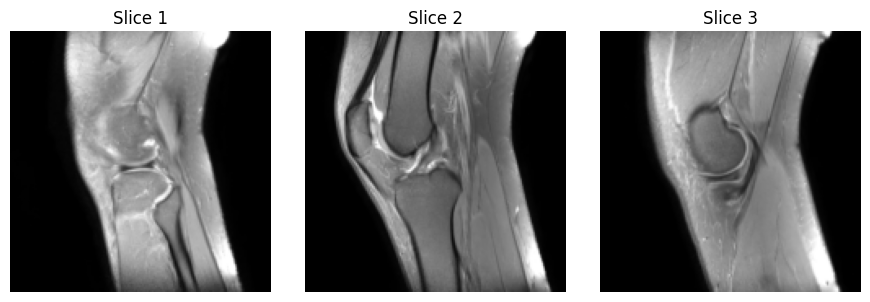

In [6]:
def select_series(study_uid, series_df):
    matches = series_df.loc[series_df['StudyInstanceUID'].astype(str) == str(study_uid)]
    if matches.empty:
        raise FileNotFoundError(f'No MRI series for study {study_uid}')
    sagittal = matches['Anatomical_Plane'].astype(str).str.lower().eq('sagittal')
    fluid = pd.to_numeric(matches['Fluid_Sensitive'], errors='coerce').eq(1)
    preferred = matches.loc[sagittal & fluid]
    if preferred.empty:
        preferred = matches.loc[sagittal]
    if preferred.empty:
        preferred = matches
    return str(preferred.iloc[0]['SeriesInstanceUID'])


def normalize_image(pixels):
    pixels = np.asarray(pixels, dtype=np.float32)
    lo, hi = np.percentile(pixels, [1, 99])
    if hi <= lo:
        return np.zeros(pixels.shape, dtype=np.uint8)
    return ((np.clip(pixels, lo, hi) - lo) / (hi - lo) * 255).astype(np.uint8)


def load_study_image(study_uid, series_df, split='train'):
    # Cache key identifies the input, shape, and preprocessing recipe.
    cache_key = hashlib.sha256(
        f'v4|{split}|{study_uid}|{IMG_SIZE}|{NUM_SLICES}'.encode()
    ).hexdigest()[:24]
    cache_path = CACHE_DIR / f'{cache_key}.npy'
    if cache_path.exists():
        return np.load(cache_path)

    series_uid = select_series(study_uid, series_df)
    folder = DATA_DIR / f'{split}_series' / str(study_uid) / series_uid
    if not folder.is_dir():
        raise FileNotFoundError(f'Cannot find series folder: {folder}')

    ordered = []
    for path in folder.iterdir():
        if not path.is_file():
            continue
        try:
            hdr = pydicom.dcmread(str(path), stop_before_pixels=True,
                                   specific_tags=['InstanceNumber'])
            ordered.append((int(getattr(hdr, 'InstanceNumber', 0)), path.name, path))
        except Exception:
            continue
    if not ordered:
        raise ValueError(f'No readable DICOM headers in {folder}')
    ordered.sort(key=lambda item: (item[0], item[1]))
    indices = np.round(np.linspace(0.2, 0.8, NUM_SLICES) * (len(ordered) - 1)).astype(int)

    channels = []
    for index in indices:
        path = ordered[index][2]
        dicom = pydicom.dcmread(str(path))
        pixels = np.asarray(dicom.pixel_array, dtype=np.float32)
        if pixels.ndim != 2:
            raise ValueError(f'Expected 2D slice; got {pixels.shape} in {path}')
        pixels = (pixels * float(getattr(dicom, 'RescaleSlope', 1.0))
                  + float(getattr(dicom, 'RescaleIntercept', 0.0)))
        image = Image.fromarray(normalize_image(pixels))
        image = image.resize(IMG_SIZE[::-1], Image.Resampling.BILINEAR)
        channels.append(np.asarray(image, dtype=np.uint8))
    result = np.stack(channels, axis=-1)
    np.save(cache_path, result)
    return result


# Quick visual check, not a new EDA investigation.
example_uid = str(gold_train_df.iloc[0]['StudyInstanceUID'])
example = load_study_image(example_uid, train_series_df)
print('One CNN input:', example.shape, example.dtype)
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for i, ax in enumerate(axes):
    ax.imshow(example[:, :, i], cmap='gray')
    ax.set_title(f'Slice {i+1}')
    ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Load training and expert-validation images

Decode the selected studies into NumPy arrays. Keep a list of failed studies rather than silently treating them as valid inputs.

In [7]:
from tqdm.auto import tqdm

def load_image_dataset(frame, series_df, split='train'):
    images, labels, ids, errors = [], [], [], []

    # tqdm displays progress, processing speed, and estimated time remaining
    for _, row in tqdm(
        frame.iterrows(),
        total=len(frame),
        desc=f"Processing {split} MRIs"
    ):
        uid = str(row['StudyInstanceUID'])

        try:
            images.append(load_study_image(uid, series_df, split=split))
            labels.append(row[LABEL_COLS].to_numpy(dtype=np.float32))
            ids.append(uid)
        except Exception as exc:
            errors.append((uid, str(exc)[:200]))

    if not images:
        raise RuntimeError('No images loaded. Check DICOM decoding and attached competition data.')

    return np.stack(images), np.stack(labels), ids, errors


X_train, y_train, image_train_ids, train_errors = load_image_dataset(
    training_rows, train_series_df
)

X_val, y_val, image_val_ids, val_errors = load_image_dataset(
    gold_val_df[['StudyInstanceUID'] + LABEL_COLS], train_series_df
)

assert not set(image_train_ids) & (set(image_val_ids) | holdout_ids)

print('Train:', X_train.shape, 'Validation:', X_val.shape)
print('Known training labels:', int((y_train >= 0).sum()), '/', y_train.size)
print('DICOM failures:', len(train_errors), len(val_errors))
print('Example failures:', (train_errors + val_errors)[:5])

if len(train_errors) > 0.1 * len(training_rows):
    print('WARNING: More than 10% of training studies failed DICOM preprocessing.')

Train: (1232, 160, 160, 3) Validation: (11, 160, 160, 3)
Known training labels: 10864 / 14784
DICOM failures: 0 0
Example failures: []


## 6. Define the masked loss and evaluation metrics

Pseudo-labels can be unknown (`-1`). The masked binary cross-entropy loss excludes those entries so the model is trained only on known labels. Report ROC-AUC and PR-AUC **for each abnormality**, then take the macro average over evaluable classes.

In [8]:
@tf.keras.utils.register_keras_serializable(package='RSNA')
def masked_binary_crossentropy(y_true, y_pred):
    known = tf.cast(y_true >= 0, tf.float32)
    safe = tf.clip_by_value(y_true, 0.0, 1.0)
    per_label = tf.keras.backend.binary_crossentropy(safe, y_pred)
    # One average loss per study, avoiding bias toward studies with more known labels.
    return tf.reduce_sum(per_label * known, axis=-1) / tf.maximum(
        tf.reduce_sum(known, axis=-1), 1.0
    )


def evaluate_predictions(actual, scores, model_name):
    rows = []
    for j, label in enumerate(LABEL_COLS):
        truth = actual[:, j]
        keep = truth >= 0
        truth = truth[keep].astype(int)
        prob = scores[keep, j]
        roc = roc_auc_score(truth, prob) if len(np.unique(truth)) == 2 else np.nan
        pr = average_precision_score(truth, prob) if (truth == 1).any() else np.nan
        rows.append({'finding': label, 'n': len(truth),
                     'positives': int((truth == 1).sum()),
                     'roc_auc': roc, 'pr_auc': pr})
    metrics = pd.DataFrame(rows)
    print(f'\n{model_name}: macro ROC-AUC={metrics.roc_auc.mean():.3f}; '
          f'macro PR-AUC={metrics.pr_auc.mean():.3f}; '
          f'evaluable ROC classes={metrics.roc_auc.notna().sum()}/12')
    display(metrics.round(3))
    return metrics

train_data = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
              .shuffle(len(X_train), seed=SEED)
              .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_data = (tf.data.Dataset.from_tensor_slices((X_val, y_val))
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))

## 7. Train MobileNetV2 with transfer learning

**Phase 1 — frozen backbone:** Train the new classification head while MobileNetV2 stays frozen. The head uses global average pooling, `Dense(256, relu)`, `Dropout(0.35)`, and 12 independent sigmoid outputs.

**Phase 2 — fine-tuning:** Unfreeze the last 40 backbone layers, keeping BatchNormalization layers frozen, and use a smaller learning rate. Select the checkpoint with the higher expert-validation macro ROC-AUC.

In [9]:
def build_model():
    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3), name='mri_slices')
    x = tf.keras.layers.Rescaling(1 / 127.5, offset=-1)(inputs)
    backbone = tf.keras.applications.MobileNetV2(
        include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3)
    )
    backbone.trainable = False
    x = backbone(x, training=False)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(256, activation='relu')(x)
    x = tf.keras.layers.Dropout(0.35)(x)
    outputs = tf.keras.layers.Dense(len(LABEL_COLS), activation='sigmoid')(x)
    return tf.keras.Model(inputs, outputs), backbone


def compile_model(model, learning_rate):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate),
                  loss=masked_binary_crossentropy)


def fit_phase(model, epochs):
    return model.fit(
        train_data, validation_data=val_data, epochs=epochs, verbose=1,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor='val_loss', patience=3, restore_best_weights=True
            ),
            tf.keras.callbacks.ReduceLROnPlateau(
                monitor='val_loss', factor=0.5, patience=2, min_lr=1e-6
            )
        ]
    )

model, backbone = build_model()
compile_model(model, 1e-3)
print('Phase 1: frozen ImageNet backbone')
history_head = fit_phase(model, HEAD_EPOCHS)
head_path = OUTPUT_DIR / 'v4_frozen_head.weights.h5'
model.save_weights(str(head_path))
head_pred = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
head_metrics = evaluate_predictions(y_val, head_pred, 'Frozen backbone')

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Phase 1: frozen ImageNet backbone
Epoch 1/8


77/77 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.6874

77/77 ━━━━━━━━━━━━━━━━━━━━ 32s 159ms/step - loss: 0.6442 - val_loss: 0.6706 - learning_rate: 0.0010
Epoch 2/8
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.5817 - val_loss: 0.6943 - learning_rate: 0.0010
Epoch 3/8
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.5618 - val_loss: 0.7301 - learning_rate: 0.0010
Epoch 4/8
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.5354 - val_loss: 0.6840 - learning_rate: 5.0000e-04

Frozen backbone: macro ROC-AUC=0.630; macro PR-AUC=0.609; evaluable ROC classes=12/12


,finding,n,positives,roc_auc,pr_auc
0,ACL,11,5,0.600,0.644
1,MCL,11,1,0.800,0.333
2,Medial Meniscus,11,5,0.500,0.487
3,Lateral Meniscus,11,4,0.893,0.804
4,Medial OA,11,4,0.857,0.830
5,Lateral OA,11,3,0.875,0.833
6,PF OA,11,4,0.286,0.317
7,Effusion,11,6,0.800,0.836
8,Synovitis,11,5,0.467,0.477
9,Baker's,11,5,0.700,0.753


In [10]:
# Phase 2: fine-tune only the last 40 layers, with BatchNorm frozen.
backbone.trainable = True
for layer in backbone.layers[:-40]:
    layer.trainable = False
for layer in backbone.layers[-40:]:
    layer.trainable = not isinstance(layer, tf.keras.layers.BatchNormalization)

compile_model(model, 3e-5)
print('Phase 2: fine-tune last 40 MobileNetV2 layers')
history_finetune = fit_phase(model, FINETUNE_EPOCHS)
finetune_path = OUTPUT_DIR / 'v4_finetuned.weights.h5'
model.save_weights(str(finetune_path))
finetune_pred = model.predict(X_val, batch_size=BATCH_SIZE, verbose=0)
finetune_metrics = evaluate_predictions(y_val, finetune_pred, 'Fine-tuned backbone')

head_auc = head_metrics['roc_auc'].mean()
finetune_auc = finetune_metrics['roc_auc'].mean()
if np.isfinite(head_auc) and (not np.isfinite(finetune_auc) or head_auc >= finetune_auc):
    model.load_weights(str(head_path))
    selected_phase = 'Frozen backbone'
    selected_metrics = head_metrics
else:
    selected_phase = 'Fine-tuned backbone'
    selected_metrics = finetune_metrics

print('Selected phase:', selected_phase)
print('Validation macro ROC-AUC:', round(selected_metrics['roc_auc'].mean(), 3))
selected_metrics.to_csv(OUTPUT_DIR / 'v4_validation_metrics.csv', index=False)
model.save_weights(str(OUTPUT_DIR / 'v4_selected.weights.h5'))

Phase 2: fine-tune last 40 MobileNetV2 layers
Epoch 1/4
77/77 ━━━━━━━━━━━━━━━━━━━━ 18s 71ms/step - loss: 0.5943 - val_loss: 0.6709 - learning_rate: 3.0000e-05
Epoch 2/4
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.5744 - val_loss: 0.7039 - learning_rate: 3.0000e-05
Epoch 3/4
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.5570 - val_loss: 0.6945 - learning_rate: 3.0000e-05
Epoch 4/4
77/77 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.5257 - val_loss: 0.6703 - learning_rate: 1.5000e-05

Fine-tuned backbone: macro ROC-AUC=0.690; macro PR-AUC=0.636; evaluable ROC classes=12/12


,finding,n,positives,roc_auc,pr_auc
0,ACL,11,5,0.633,0.678
1,MCL,11,1,0.600,0.200
2,Medial Meniscus,11,5,0.800,0.821
3,Lateral Meniscus,11,4,0.821,0.646
4,Medial OA,11,4,0.964,0.950
5,Lateral OA,11,3,0.875,0.639
6,PF OA,11,4,0.536,0.427
7,Effusion,11,6,0.833,0.877
8,Synovitis,11,5,0.567,0.574
9,Baker's,11,5,0.867,0.911


Selected phase: Fine-tuned backbone
Validation macro ROC-AUC: 0.69


### Expert-validation comparison

Compare the frozen and fine-tuned phases on the same 11 expert-labeled studies.


In [15]:
# Compare the two training phases on the same 11 expert-labeled studies
baseline_comparison = pd.DataFrame({
    "Model": ["Frozen backbone", "Fine-tuned backbone"],
    "Macro ROC-AUC": [
        head_metrics["roc_auc"].mean(),
        finetune_metrics["roc_auc"].mean()
    ],
    "Macro PR-AUC": [
        head_metrics["pr_auc"].mean(),
        finetune_metrics["pr_auc"].mean()
    ]
})

display(baseline_comparison.round(3))

# How much did fine-tuning change ROC-AUC?
improvement = (
    finetune_metrics["roc_auc"].mean()
    - head_metrics["roc_auc"].mean()
)

print(f"Fine-tuning ROC-AUC difference: {improvement:+.3f}")

,Model,Macro ROC-AUC,Macro PR-AUC
0,Frozen backbone,0.63,0.609
1,Fine-tuned backbone,0.69,0.636


Fine-tuning ROC-AUC difference: +0.061


## 8. Evaluate on 300 non-training studies (weak-label reference)

These 300 studies were **not used to train the CNN**, but their reference labels are LLM-derived report scores, **not expert diagnoses**. For this supplementary analysis, scores above 0.5 are treated as positive, below 0.5 as negative, and exactly 0.5 as uncertain/excluded. The resulting AUC measures agreement with weak labels, not clinical accuracy.

In [11]:
# Load 300 unseen MRI studies using our existing preprocessing function
X_eval, y_eval, eval_ids, eval_errors = load_image_dataset(
    eval_df,
    train_series_df,
    split="train"
)

print("Evaluation images:", X_eval.shape)
print("Evaluation labels:", y_eval.shape)
print("DICOM loading errors:", len(eval_errors))

Evaluation images: (300, 160, 160, 3)
Evaluation labels: (300, 12)
DICOM loading errors: 0


In [13]:
# Convert LLM scores into binary reference labels
# Scores above 0.5 = positive
# Scores below 0.5 = negative
# Scores exactly 0.5 = uncertain, excluded from evaluation

y_eval_binary = np.where(
    np.isclose(y_eval, 0.5),
    np.nan,
    (y_eval > 0.5).astype(float)
)

# Check how many usable labels remain for each abnormality
label_summary = pd.DataFrame({
    "Finding": LABEL_COLS,
    "Usable": np.sum(~np.isnan(y_eval_binary), axis=0),
    "Positive": np.nansum(y_eval_binary, axis=0).astype(int),
    "Uncertain": np.sum(np.isnan(y_eval_binary), axis=0)
})

display(label_summary)

,Finding,Usable,Positive,Uncertain
0,ACL,281,58,19
1,MCL,273,42,27
2,Medial Meniscus,286,165,14
3,Lateral Meniscus,272,88,28
4,Medial OA,245,131,55
5,Lateral OA,224,85,76
6,PF OA,247,140,53
7,Effusion,274,197,26
8,Synovitis,275,198,25
9,Baker's,154,66,146


In [14]:
# Use the V4 model selected by the original validation process
# The notebook already restored its selected weights.

# Predict the 12 abnormalities for all 300 MRI studies
eval_pred = model.predict(
    X_eval,
    batch_size=BATCH_SIZE,
    verbose=1
)

# Calculate metrics separately for each abnormality
results = []

for i, finding in enumerate(LABEL_COLS):

    # Exclude uncertain LLM labels (NaN)
    valid = ~np.isnan(y_eval_binary[:, i])

    # Reference labels and CNN predictions
    y_true = y_eval_binary[valid, i].astype(int)
    y_score = eval_pred[valid, i]

    # ROC-AUC requires both positive and negative examples
    if len(np.unique(y_true)) == 2:
        roc = roc_auc_score(y_true, y_score)
        pr = average_precision_score(y_true, y_score)
    else:
        roc, pr = np.nan, np.nan

    results.append({
        "Finding": finding,
        "N": len(y_true),
        "ROC-AUC": roc,
        "PR-AUC": pr
    })

# Display results
eval_metrics = pd.DataFrame(results)

display(eval_metrics.round(3))

print(
    "300-study weak-label macro ROC-AUC:",
    round(eval_metrics["ROC-AUC"].mean(), 3)
)

print(
    "300-study weak-label macro PR-AUC:",
    round(eval_metrics["PR-AUC"].mean(), 3)
)

15/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step

19/19 ━━━━━━━━━━━━━━━━━━━━ 15s 586ms/step


,Finding,N,ROC-AUC,PR-AUC
0,ACL,281,0.601,0.293
1,MCL,273,0.689,0.314
2,Medial Meniscus,286,0.624,0.690
3,Lateral Meniscus,272,0.635,0.429
4,Medial OA,245,0.755,0.786
5,Lateral OA,224,0.695,0.527
6,PF OA,247,0.742,0.770
7,Effusion,274,0.753,0.877
8,Synovitis,275,0.579,0.772
9,Baker's,154,0.696,0.599


300-study weak-label macro ROC-AUC: 0.663
300-study weak-label macro PR-AUC: 0.563


### Weak-label comparison

Compare both training phases against the same 300 weak-label reference studies.


In [16]:
# Calculate macro ROC-AUC while excluding uncertain labels
def weak_label_auc(predictions):
    scores = []

    for i in range(len(LABEL_COLS)):
        valid = ~np.isnan(y_eval_binary[:, i])

        y_true = y_eval_binary[valid, i].astype(int)
        y_pred = predictions[valid, i]

        if len(np.unique(y_true)) == 2:
            scores.append(roc_auc_score(y_true, y_pred))

    return np.mean(scores)


# 1. Evaluate frozen-backbone model
model.load_weights(str(head_path))

frozen_pred = model.predict(
    X_eval, batch_size=BATCH_SIZE, verbose=0
)

frozen_auc = weak_label_auc(frozen_pred)


# 2. Restore selected model and evaluate
model.load_weights(
    str(OUTPUT_DIR / "v4_selected.weights.h5")
)

selected_pred = model.predict(
    X_eval, batch_size=BATCH_SIZE, verbose=0
)

selected_auc = weak_label_auc(selected_pred)


# 3. Compare results
comparison = pd.DataFrame({
    "Model": ["Frozen backbone", selected_phase],
    "300-study ROC-AUC": [frozen_auc, selected_auc]
})

display(comparison.round(3))

print(f"Difference: {selected_auc - frozen_auc:+.3f}")

,Model,300-study ROC-AUC
0,Frozen backbone,0.606
1,Fine-tuned backbone,0.663


Difference: +0.057


## 9. Create a submission CSV (visible test studies)

Load the selected checkpoint and predict each abnormality for the visible test studies. Match the required `sample_submission.csv` column order and validate the prediction range.

**Competition note:** This training notebook was used for development. The successful Kaggle code submission used a separate inference-only notebook with saved model weights so it did not need to retrain on the hidden test set.

In [18]:
test_rows = test_df[['StudyInstanceUID']].copy()
for col in LABEL_COLS:
    test_rows[col] = -1.0

X_test, _, test_ids, test_errors = load_image_dataset(
    test_rows, test_series_df, split='test'
)
if test_errors or len(test_ids) != len(test_df):
    raise RuntimeError(f'Not all test studies decoded: {test_errors}')

# Restore the best model selected during validation
model.load_weights(str(OUTPUT_DIR / 'v4_selected.weights.h5'))

prob = model.predict(X_test, batch_size=BATCH_SIZE, verbose=0)
submission_predictions = pd.DataFrame(prob, columns=LABEL_COLS)
submission_predictions.insert(0, 'StudyInstanceUID', test_ids)
submission = sample_submission[['StudyInstanceUID']].merge(
    submission_predictions, on='StudyInstanceUID', how='left', validate='one_to_one'
)
assert submission.columns.tolist() == sample_submission.columns.tolist()
assert submission.shape == sample_submission.shape
assert submission[LABEL_COLS].notna().all().all()
assert np.isfinite(submission[LABEL_COLS].to_numpy()).all()
assert submission[LABEL_COLS].ge(0).all().all() and submission[LABEL_COLS].le(1).all().all()
submission.to_csv(OUTPUT_DIR / 'submission.csv', index=False)
print('Saved /kaggle/working/submission.csv')
display(submission.head())

Saved /kaggle/working/submission.csv


,StudyInstanceUID,ACL,MCL,Medial Meniscus,Lateral Meniscus,Medial OA,Lateral OA,PF OA,Effusion,Synovitis,Baker's,Contusion,Fracture
0,1.2.826.0.1.3680043.8.498.10047035057544427318...,0.067144,0.041797,0.448341,0.224265,0.467747,0.229616,0.636272,0.872313,0.687607,0.667883,0.282057,0.046757
1,1.2.826.0.1.3680043.8.498.10062861783145312629...,0.113087,0.094466,0.634710,0.229760,0.491654,0.462365,0.718279,0.440531,0.733711,0.279456,0.191158,0.115406
2,1.2.826.0.1.3680043.8.498.10067514707072572280...,0.482903,0.220104,0.632443,0.393875,0.485072,0.328942,0.608284,0.815789,0.769482,0.618206,0.542271,0.117691


## 10. Results and takeaways

| Evaluation | Macro ROC-AUC | Macro PR-AUC | Reference |
|---|---:|---:|---|
| Frozen backbone | 0.630 | 0.609 | 11 expert-labeled validation studies |
| Fine-tuned backbone (selected) | **0.690** | **0.636** | 11 expert-labeled validation studies |
| Selected CNN, supplementary evaluation | 0.663 | 0.563 | 300 non-training studies, LLM-derived labels |
| Frozen CNN, supplementary evaluation | 0.606 | — | Same 300 weak-label studies |
| Kaggle public leaderboard | **0.631** | — | Competition public score; leaderboard metric reported separately |

**What I learned:** Fine-tuning the final MobileNetV2 layers improved validation ranking performance compared with a frozen backbone. DICOM preprocessing and fixed-size three-slice inputs made it possible to reuse a 2D image classifier for MRI studies. The biggest challenge was the shortage of expert-labeled training data.

**Limitations:** The expert validation split has only 11 studies, and the previously inspected 15-study holdout is not an untouched test set. The 300-study results use weak labels and are not independent clinical validation. The external labels' provenance and independence from the expert labels have not been fully verified. The model should not be used for diagnosis.

**Possible future improvements (not performed):** More expert-labeled cases, improved slice/series selection, richer 3D MRI representations, and an independently labeled evaluation set.

**Execution note:** Code and saved outputs come from the completed Kaggle run. The notebook was edited for presentation and **has not been rerun after cleanup**.